# Imports

In [78]:
from loader import *

# Exploratory Data Analysis

In [144]:
outcome = outcome_data.copy()
intake = intake_data.copy()
#Outcome Data Cleaning

def convert_to_days(age_str):
    if pd.isna(age_str) or not isinstance(age_str, str):
        return None
    # Clean up the string (lowercase, remove extra spaces)
    age_str = age_str.lower().strip()
    parts = age_str.split()
    if len(parts) < 2:
        return None
    try:
        num = float(parts[0])
    except ValueError:
        return None
    unit = parts[1]
    if 'year' in unit:
        return num * 365.25 
    elif 'month' in unit:
        return num * 30.44 
    elif 'week' in unit:
        return num * 7
    elif 'day' in unit:
        return num

outcome['DateTime'] = pd.to_datetime(outcome['DateTime'].str.slice(0, 10))
outcome['Date of Birth'] = pd.to_datetime(outcome['Date of Birth'])
outcome['Age in Days upon Outcome'] = outcome['Age upon Outcome'].apply(convert_to_days)
outcome = outcome[outcome['Age in Days upon Outcome'] >= 0]
outcome = outcome.dropna(subset=['Outcome Type'])
outcome['IsEuthanized'] = outcome['Outcome Type'].apply(lambda x: 1 if x == 'Euthanasia' else 0)
outcome.info()
print(outcome.describe())
outcome.head()



<class 'pandas.DataFrame'>
Index: 173710 entries, 0 to 173774
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   Animal ID                 173710 non-null  str           
 1   Date of Birth             173710 non-null  datetime64[us]
 2   Name                      123952 non-null  str           
 3   DateTime                  173710 non-null  datetime64[us]
 4   MonthYear                 173710 non-null  str           
 5   Outcome Type              173710 non-null  str           
 6   Outcome Subtype           79646 non-null   str           
 7   Animal Type               173710 non-null  str           
 8   Sex upon Outcome          173709 non-null  str           
 9   Age upon Outcome          173710 non-null  str           
 10  Breed                     173710 non-null  str           
 11  Color                     173710 non-null  str           
 12  Age in Days upon O

,Animal ID,Date of Birth,Name,DateTime,MonthYear,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color,Age in Days upon Outcome,IsEuthanized
0,A668305,2012-12-01,NaN,2013-12-02,12-2013,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Brown/Yellow,365.25,0
1,A673335,2012-02-22,NaN,2014-02-22,02-2014,Euthanasia,Suffering,Other,Unknown,2 years,Raccoon,Black/Gray,730.50,1
2,A675999,2013-04-03,NaN,2014-04-07,04-2014,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Green,365.25,0
4,A680855,2014-05-25,NaN,2014-06-10,06-2014,Transfer,Partner,Bird,Unknown,2 weeks,Duck,Yellow/Black,14.00,0
5,A680857,2014-05-25,NaN,2014-06-10,06-2014,Transfer,Partner,Bird,Unknown,2 weeks,Duck,Yellow/Black,14.00,0


In [146]:
#Intake Data Cleaning
intake['DateTime_intake'] = pd.to_datetime(intake['DateTime'].str.slice(0,10))

#print(intake.head())
#intake.info()

#Important columns to consider for analysis
intake_cols = ['Animal ID', 'Name', 'DateTime_intake', 'Intake Type', 'Intake Condition', 'Animal Type', 'Sex upon Intake', 'Age upon Intake', 'Breed', 'Color']

#Merged dataset
#Same animal can have multiple intake and outcome records
#Need to match intake and outcome records based on the outcome date that comes right after the intake date for the same animal
intake_sorted = intake[intake_cols].sort_values('DateTime_intake')
outcome_sorted = outcome.drop(columns =['Name', 'MonthYear']).sort_values('DateTime')

merged_data = pd.merge_asof(
    outcome_sorted,
    intake_sorted,
    left_on='DateTime',  
    right_on = 'DateTime_intake',        
    by='Animal ID',         
    direction='backward'
)

print(merged_data[merged_data['Animal ID'] == 'A006100'])


      Animal ID Date of Birth   DateTime     Outcome Type Outcome Subtype  \
7273    A006100    2007-07-09 2014-03-08  Return to Owner             NaN   
22689   A006100    2007-07-09 2014-12-20  Return to Owner             NaN   
76016   A006100    2007-07-09 2017-12-07  Return to Owner             NaN   

      Animal Type_x Sex upon Outcome Age upon Outcome               Breed_x  \
7273            Dog    Neutered Male          6 years  Spinone Italiano Mix   
22689           Dog    Neutered Male          7 years  Spinone Italiano Mix   
76016           Dog    Neutered Male         10 years  Spinone Italiano Mix   

            Color_x  ...  IsEuthanized   Name DateTime_intake    Intake Type  \
7273   Yellow/White  ...             0  Scamp      2014-03-07  Public Assist   
22689  Yellow/White  ...             0  Scamp      2014-12-19  Public Assist   
76016  Yellow/White  ...             0  Scamp      2017-12-07          Stray   

      Intake Condition Animal Type_y Sex upon Intake 

In [147]:
print(outcome[outcome['Animal ID'] == 'A006100'])
print(intake[intake['Animal ID'] == 'A006100'])

      Animal ID Date of Birth   Name   DateTime MonthYear     Outcome Type  \
1891    A006100    2007-07-09  Scamp 2017-12-07   12-2017  Return to Owner   
9637    A006100    2007-07-09  Scamp 2014-03-08   03-2014  Return to Owner   
25064   A006100    2007-07-09  Scamp 2014-12-20   12-2014  Return to Owner   

      Outcome Subtype Animal Type Sex upon Outcome Age upon Outcome  \
1891              NaN         Dog    Neutered Male         10 years   
9637              NaN         Dog    Neutered Male          6 years   
25064             NaN         Dog    Neutered Male          7 years   

                      Breed         Color  Age in Days upon Outcome  \
1891   Spinone Italiano Mix  Yellow/White                   3652.50   
9637   Spinone Italiano Mix  Yellow/White                   2191.50   
25064  Spinone Italiano Mix  Yellow/White                   2556.75   

       IsEuthanized  
1891              0  
9637              0  
25064             0  
      Animal ID   Name       

In [149]:
print(f"Original Outcome rows: {len(outcome)}")
print(f"Original Intake rows: {len(intake)}")

outcome_ids = set(outcome['Animal ID'])
intake_ids = set(intake['Animal ID'])


print(f"Unique IDs in Intake: {len(intake_ids)}")
print(f"Unique IDs in Outcome: {len(outcome_ids)}")

# Find how many overlap
common_ids = intake_ids.intersection(outcome_ids)
print(f"IDs present in BOTH datasets: {len(common_ids)}")

# Find how many are missing from intake
missing_from_intake = outcome_ids - intake_ids
print(f"Outcome IDs missing from Intake file: {len(missing_from_intake)}")



Original Outcome rows: 173710
Original Intake rows: 173812
Unique IDs in Intake: 156287
Unique IDs in Outcome: 156191
IDs present in BOTH datasets: 155377
Outcome IDs missing from Intake file: 814


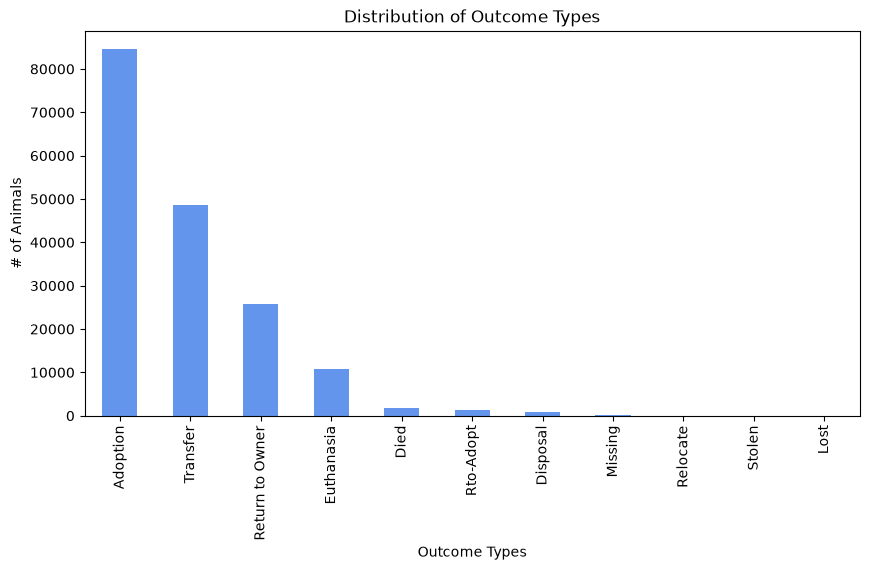

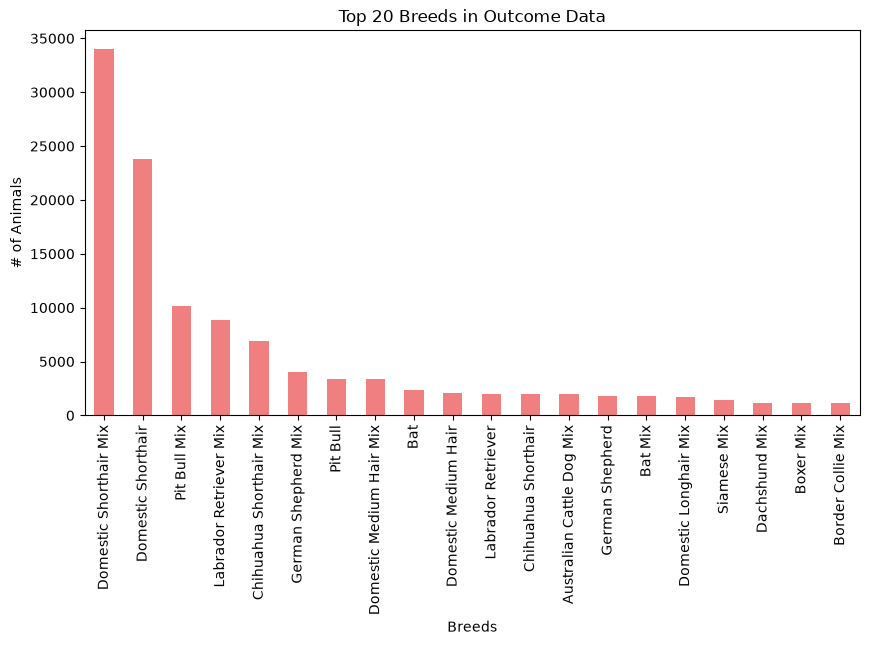

Breed
Domestic Shorthair Mix       34039
Domestic Shorthair           23833
Pit Bull Mix                 10148
Labrador Retriever Mix        8811
Chihuahua Shorthair Mix       6916
German Shepherd Mix           4053
Pit Bull                      3404
Domestic Medium Hair Mix      3377
Bat                           2351
Domestic Medium Hair          2101
Labrador Retriever            2029
Chihuahua Shorthair           2009
Australian Cattle Dog Mix     1991
German Shepherd               1822
Bat Mix                       1754
Domestic Longhair Mix         1687
Siamese Mix                   1474
Dachshund Mix                 1191
Boxer Mix                     1185
Border Collie Mix             1150
Name: count, dtype: int64
-------------------------------------
Animal Type
Dog          94466
Cat          69385
Other         8949
Bird           876
Livestock       34
Name: count, dtype: int64


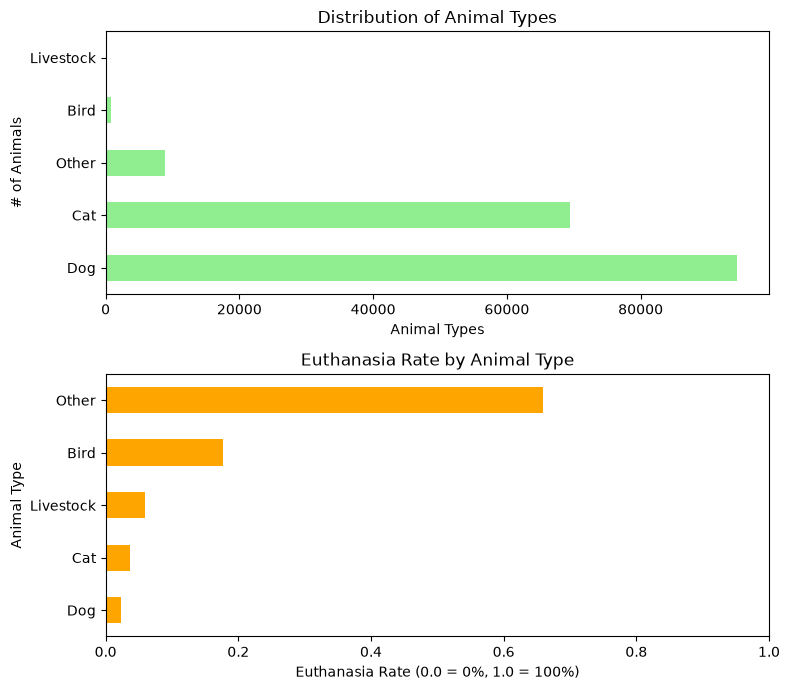

Sex upon Outcome
Neutered Male    60917
Spayed Female    55251
Intact Male      22253
Intact Female    21799
Unknown          13489
Name: count, dtype: int64


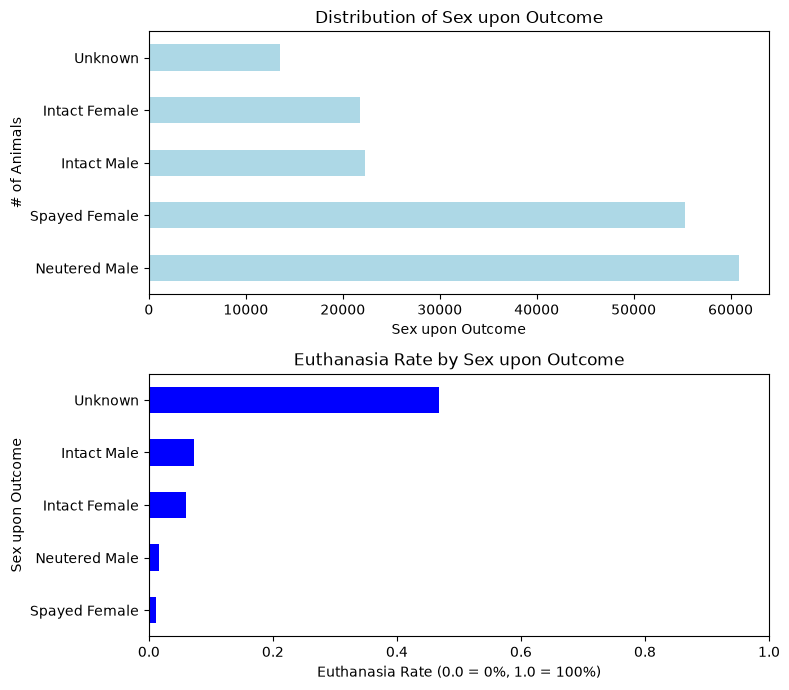

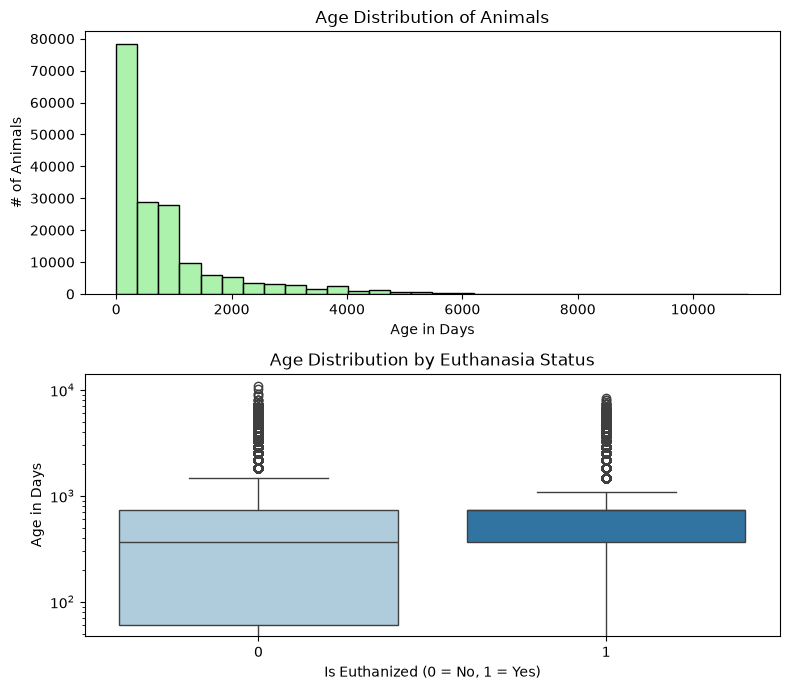

In [150]:
#Distirbutions of Outcome Types
outcome_types = outcome['Outcome Type'].value_counts()
plt.figure(figsize=(10, 5))
outcome_types.plot(kind='bar', color='cornflowerblue')
plt.title('Distribution of Outcome Types')
plt.xlabel('Outcome Types')
plt.ylabel('# of Animals')
plt.show()

#Top 20 Breeds distribution
top20_breeds = outcome['Breed'].value_counts().head(20)
plt.figure(figsize=(10, 5))
top20_breeds.plot(kind='bar', color='lightcoral')
plt.title('Top 20 Breeds in Outcome Data')
plt.xlabel('Breeds')
plt.ylabel('# of Animals')
plt.show()
print(top20_breeds)
print("-------------------------------------")


#Animal Type Distibution and Euthanasia Rate
animal_types = outcome['Animal Type'].value_counts()
print(animal_types)
fig, axs = plt.subplots(2, 1, figsize=(8, 7))
animal_types.plot(kind='barh', color='lightgreen', ax = axs[0])
axs[0].set_title('Distribution of Animal Types')
axs[0].set_xlabel('Animal Types')
axs[0].set_ylabel('# of Animals')

animaltype_rates = outcome.groupby('Animal Type')['IsEuthanized'].mean().sort_values()
animaltype_rates.plot(kind='barh', color='orange', ax=axs[1])
axs[1].set_title(f'Euthanasia Rate by {column_name}')
axs[1].set_xlabel('Euthanasia Rate (0.0 = 0%, 1.0 = 100%)')
axs[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

#Sex Distribution and Euthanasia Rate by sex upon outcome
sex_counts = outcome['Sex upon Outcome'].value_counts()
print(sex_counts)
fig, axs = plt.subplots(2, 1, figsize=(8, 7))
sex_counts.plot(kind='barh', color='lightblue', ax = axs[0])
axs[0].set_title('Distribution of Sex upon Outcome')
axs[0].set_xlabel('Sex upon Outcome')
axs[0].set_ylabel('# of Animals')

sex_rates = outcome.groupby('Sex upon Outcome')['IsEuthanized'].mean().sort_values()
sex_rates.plot(kind='barh', color='blue', ax=axs[1])
axs[1].set_title(f'Euthanasia Rate by Sex upon Outcome')
axs[1].set_xlabel('Euthanasia Rate (0.0 = 0%, 1.0 = 100%)')
axs[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

#Age Distribution and Euthanasia Rate by Age
fig, axs = plt.subplots(2, 1, figsize=(8, 7))
sns.histplot(outcome['Age in Days upon Outcome'].dropna(), bins=30, color='lightgreen', edgecolor='black', ax = axs[0])
axs[0].set_title('Age Distribution of Animals')
axs[0].set_xlabel('Age in Days')
axs[0].set_ylabel('# of Animals')

sns.boxplot(data=outcome, x='IsEuthanized', y='Age in Days upon Outcome', hue = 'IsEuthanized', palette='Paired', legend = False)
axs[1].set_title('Age Distribution by Euthanasia Status')
axs[1].set_xlabel('Is Euthanized (0 = No, 1 = Yes)')
axs[1].set_ylabel('Age in Days')
axs[1].set_yscale('log')
plt.tight_layout()
plt.show()
